# Sea-level data: EDA, cleaning, and preparation

Read `raw_dataset/1_sea_level.csv`, inspect the original data, clean and prepare it, inspect the prepared data, then save a CSV in `clean_dataset/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
SEA_LEVEL_COLUMNS = [
    "sea_level_cmems_m",
    "sea_level_hycom_mean_m",
    "sea_level_hycom_max_m",
    "sea_level_hycom_min_m",
]


In [2]:
project_dir = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "raw_dataset" / "1_sea_level.csv").is_file()),
    None,
)
if project_dir is None:
    raise FileNotFoundError(f"Cannot find raw_dataset/1_sea_level.csv from {Path.cwd()}")

source_path = project_dir / "raw_dataset" / "1_sea_level.csv"
raw_df = pd.read_csv(source_path, encoding="utf-8-sig")
missing_columns = sorted(set(SEA_LEVEL_COLUMNS + ["date", "unit_level", "district_code"]) - set(raw_df.columns))
if missing_columns:
    raise ValueError(f"Required columns are missing from {source_path.name}: {missing_columns}")

print(f"Source: {source_path}")
print(f"Rows: {len(raw_df):,} | Columns: {len(raw_df.columns)}")
print(f"Date range: {raw_df['date'].min()} to {raw_df['date'].max()}")
print("Rows by unit level:")
display(raw_df["unit_level"].value_counts(dropna=False).to_frame("rows"))
print("Data types:")
display(raw_df.dtypes.rename("dtype").to_frame())
print("First rows:")
display(raw_df.head())


Source: c:\Users\sitti\OneDrive\Desktop\Nahh ahhh v4\raw_dataset\1_sea_level.csv
Rows: 41,648 | Columns: 13
Date range: 2020-01-01 to 2025-12-31
Rows by unit level:


,rows
unit_level,
amphoe,39456
province,2192


Data types:


,dtype
date,object
year,int64
month,int64
day,int64
doy,int64
unit_level,object
province,object
district,object
district_code,int64
sea_level_cmems_m,float64


First rows:


,date,year,month,day,doy,unit_level,province,district,district_code,sea_level_cmems_m,sea_level_hycom_mean_m,sea_level_hycom_max_m,sea_level_hycom_min_m
0,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Bang Khan,26738,NaN,0.729109,0.771184,0.679884
1,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Cha-uat,26739,NaN,0.729109,0.771184,0.679884
2,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Chawang,26740,NaN,0.729109,0.771184,0.679884
3,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Chian Yai,26741,NaN,0.729109,0.771184,0.679884
4,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Hua Sai,26742,NaN,0.729109,0.771184,0.679884


## 1. EDA on the original data

Missing values:


,missing_rows
sea_level_cmems_m,16758
sea_level_hycom_max_m,9158
sea_level_hycom_mean_m,9158
sea_level_hycom_min_m,9158
date,0
doy,0
day,0
month,0
year,0
district_code,0


Duplicate rows: 0
Duplicate date + unit + district keys: 0
Sea-level summary statistics:


,count,mean,std,min,25%,50%,75%,max
sea_level_cmems_m,24890.0,0.7006,0.1034,0.4666,0.6240,0.6775,0.7674,1.0292
sea_level_hycom_mean_m,32490.0,0.6463,0.0692,0.4340,0.5956,0.6386,0.6920,0.8747
sea_level_hycom_max_m,32490.0,0.6785,0.0721,0.4639,0.6239,0.6708,0.7236,0.9229
sea_level_hycom_min_m,32490.0,0.6142,0.0678,0.4044,0.5665,0.6081,0.6595,0.8247


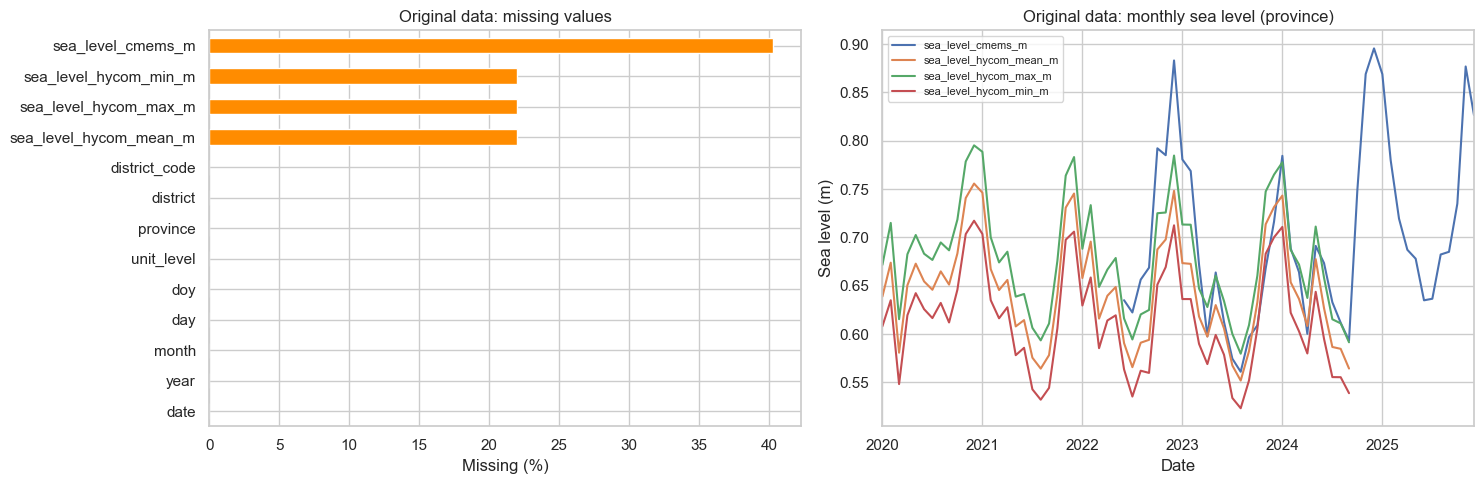

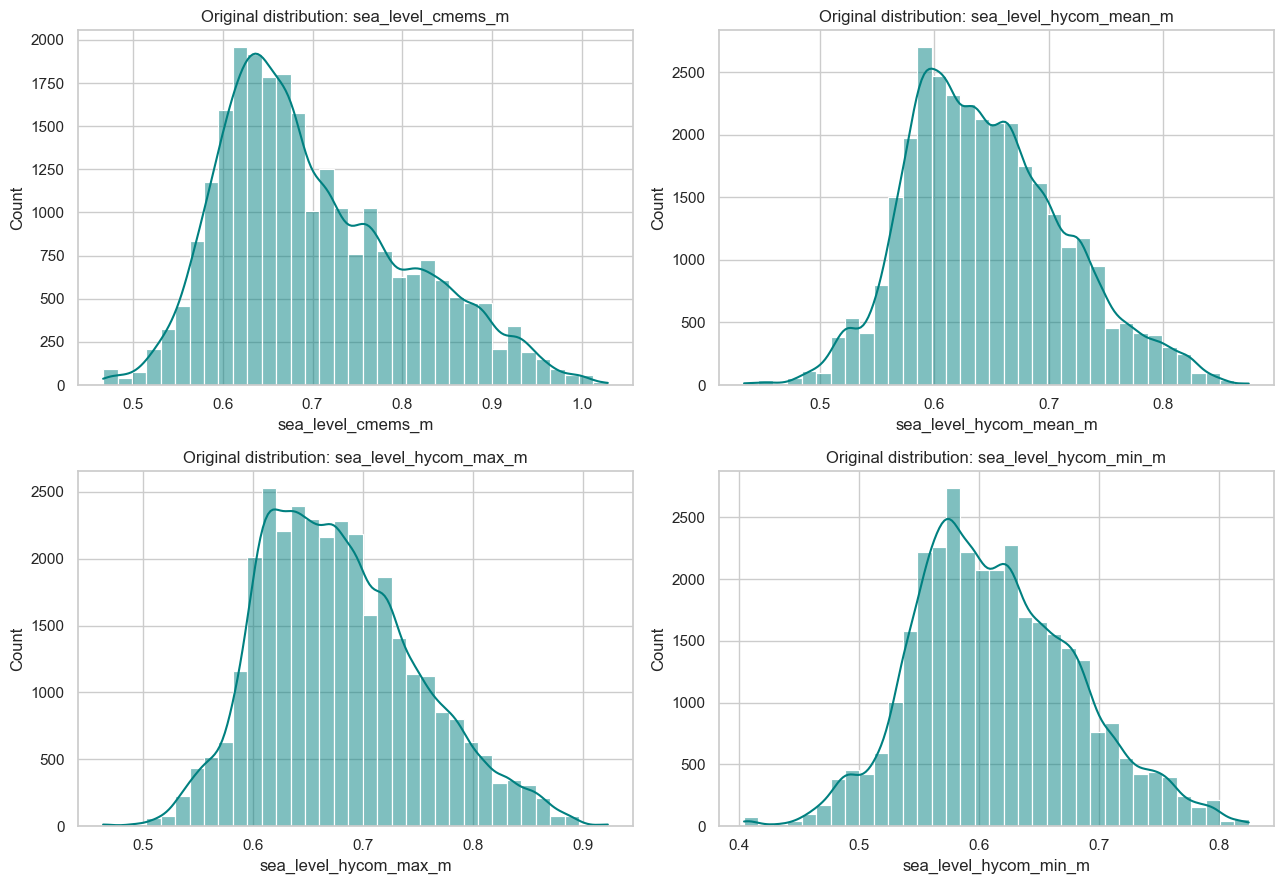

In [3]:
eda_df = raw_df.copy()
eda_df["date"] = pd.to_datetime(eda_df["date"], errors="coerce")
print("Missing values:")
display(eda_df.isna().sum().sort_values(ascending=False).rename("missing_rows").to_frame())
print("Duplicate rows:", int(eda_df.duplicated().sum()))
print("Duplicate date + unit + district keys:",
      int(eda_df.duplicated(["date", "unit_level", "district_code"]).sum()))
print("Sea-level summary statistics:")
display(eda_df[SEA_LEVEL_COLUMNS].describe().T.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
missing_pct = eda_df.isna().mean().mul(100).sort_values().tail(15)
missing_pct.plot(kind="barh", ax=axes[0], color="darkorange")
axes[0].set(title="Original data: missing values", xlabel="Missing (%)")

province_df = eda_df.loc[eda_df["unit_level"].eq("province")].set_index("date").sort_index()
monthly = province_df[SEA_LEVEL_COLUMNS].resample("MS").mean()
monthly.plot(ax=axes[1])
axes[1].set(title="Original data: monthly sea level (province)", xlabel="Date", ylabel="Sea level (m)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for column, ax in zip(SEA_LEVEL_COLUMNS, axes.flat):
    sns.histplot(eda_df, x=column, bins=35, kde=True, ax=ax, color="teal")
    ax.set_title(f"Original distribution: {column}")
plt.tight_layout()
plt.show()


## 2. Clean the data

In [4]:
df_clean = raw_df.copy()
rows_before = len(df_clean)
df_clean["date"] = pd.to_datetime(df_clean["date"], errors="coerce")

text_columns = df_clean.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    df_clean[column] = (df_clean[column].astype("string").str.strip()
                        .str.replace(r"\s+", " ", regex=True))

numeric_columns = [column for column in df_clean.columns if column not in text_columns and column != "date"]
for column in numeric_columns:
    df_clean[column] = pd.to_numeric(df_clean[column], errors="coerce")

df_clean = df_clean.dropna(subset=["date", "unit_level", "district_code"]).copy()
df_clean = df_clean.drop_duplicates()
df_clean = df_clean.drop_duplicates(
    subset=["date", "unit_level", "district_code"], keep="first"
)
df_clean["district_code"] = df_clean["district_code"].astype("int64")

print(f"Rows before cleaning: {rows_before:,}")
print(f"Rows after cleaning: {len(df_clean):,}")
print(f"Rows removed: {rows_before - len(df_clean):,}")
print("Missing values after structural cleaning:")
display(df_clean.isna().sum().sort_values(ascending=False).rename("missing_rows").to_frame())
print("Cleaned sample:")
display(df_clean.head())


Rows before cleaning: 41,648
Rows after cleaning: 41,648
Rows removed: 0
Missing values after structural cleaning:


,missing_rows
sea_level_cmems_m,16758
sea_level_hycom_max_m,9158
sea_level_hycom_mean_m,9158
sea_level_hycom_min_m,9158
date,0
doy,0
day,0
month,0
year,0
district_code,0


Cleaned sample:


,date,year,month,day,doy,unit_level,province,district,district_code,sea_level_cmems_m,sea_level_hycom_mean_m,sea_level_hycom_max_m,sea_level_hycom_min_m
0,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Bang Khan,26738,NaN,0.729109,0.771184,0.679884
1,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Cha-uat,26739,NaN,0.729109,0.771184,0.679884
2,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Chawang,26740,NaN,0.729109,0.771184,0.679884
3,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Chian Yai,26741,NaN,0.729109,0.771184,0.679884
4,2020-01-01,2020,1,1,1,amphoe,นครศรีธรรมราช,Hua Sai,26742,NaN,0.729109,0.771184,0.679884


## 3. Prepare the data

The source has long periods with no CMEMS or HYCOM measurements (including complete missing years). Keep those values missing rather than inventing measurements; add explicit missing-value flags for analysis.

In [5]:
df_prepared = df_clean.copy()

for column in SEA_LEVEL_COLUMNS:
    df_prepared[f"{column}_missing"] = df_prepared[column].isna().astype("int8")

df_prepared["sea_level_available_count"] = df_prepared[SEA_LEVEL_COLUMNS].notna().sum(axis=1).astype("int8")
# Rebuild calendar fields from the parsed date so they cannot disagree with it.
df_prepared["year"] = df_prepared["date"].dt.year.astype("int16")
df_prepared["month"] = df_prepared["date"].dt.month.astype("int8")
df_prepared["day"] = df_prepared["date"].dt.day.astype("int8")
df_prepared["doy"] = df_prepared["date"].dt.dayofyear.astype("int16")
df_prepared = df_prepared.sort_values(
    ["date", "unit_level", "district_code"]
).reset_index(drop=True)

assert df_prepared["date"].notna().all()
assert not df_prepared.duplicated(["date", "unit_level", "district_code"]).any()
assert df_prepared["sea_level_available_count"].between(0, len(SEA_LEVEL_COLUMNS)).all()
print(f"Prepared shape: {df_prepared.shape}")
print("Available sea-level measurements per row:")
display(df_prepared["sea_level_available_count"].value_counts().sort_index().rename("rows").to_frame())


Prepared shape: (41648, 18)
Available sea-level measurements per row:


,rows
sea_level_available_count,
1,9158
3,16758
4,15732


## 4. EDA on the cleaned and prepared data

Rows: 41,648 | Columns: 18
Date range: 2020-01-01 to 2025-12-31
Prepared data types:


,dtype
date,datetime64[ns]
year,int16
month,int8
day,int8
doy,int16
unit_level,string[python]
province,string[python]
district,string[python]
district_code,int64
sea_level_cmems_m,float64


Prepared sea-level summary:


,count,mean,std,min,25%,50%,75%,max
sea_level_cmems_m,24890.0,0.7006,0.1034,0.4666,0.6240,0.6775,0.7674,1.0292
sea_level_hycom_mean_m,32490.0,0.6463,0.0692,0.4340,0.5956,0.6386,0.6920,0.8747
sea_level_hycom_max_m,32490.0,0.6785,0.0721,0.4639,0.6239,0.6708,0.7236,0.9229
sea_level_hycom_min_m,32490.0,0.6142,0.0678,0.4044,0.5665,0.6081,0.6595,0.8247


Missing percentage by sea-level source:


,missing_pct
sea_level_cmems_m,40.24
sea_level_hycom_mean_m,21.99
sea_level_hycom_max_m,21.99
sea_level_hycom_min_m,21.99


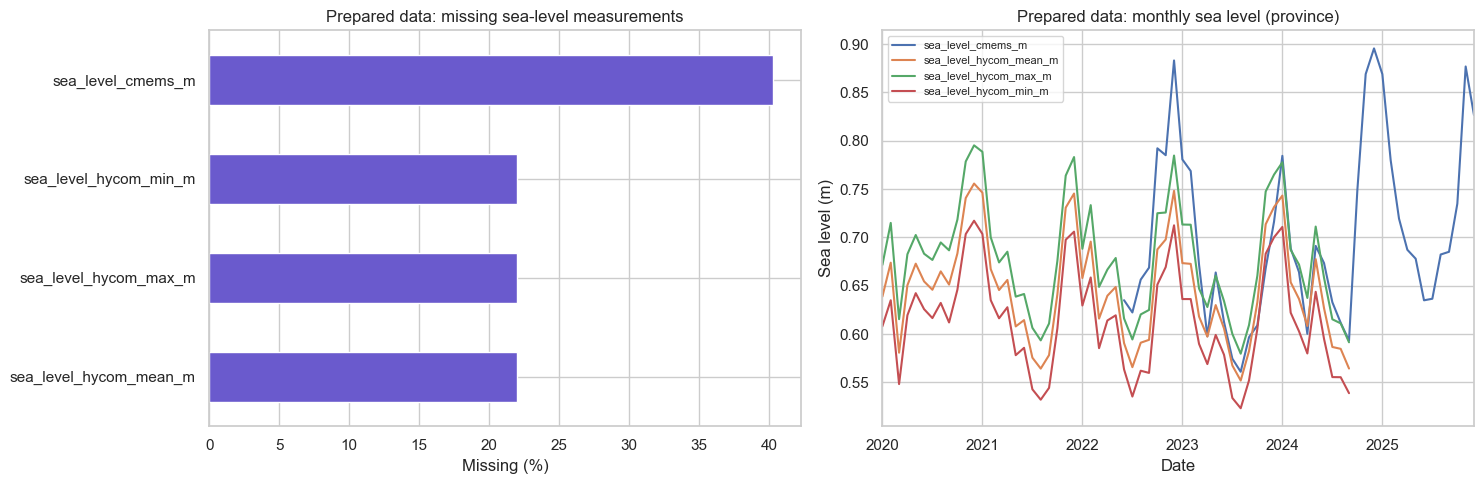

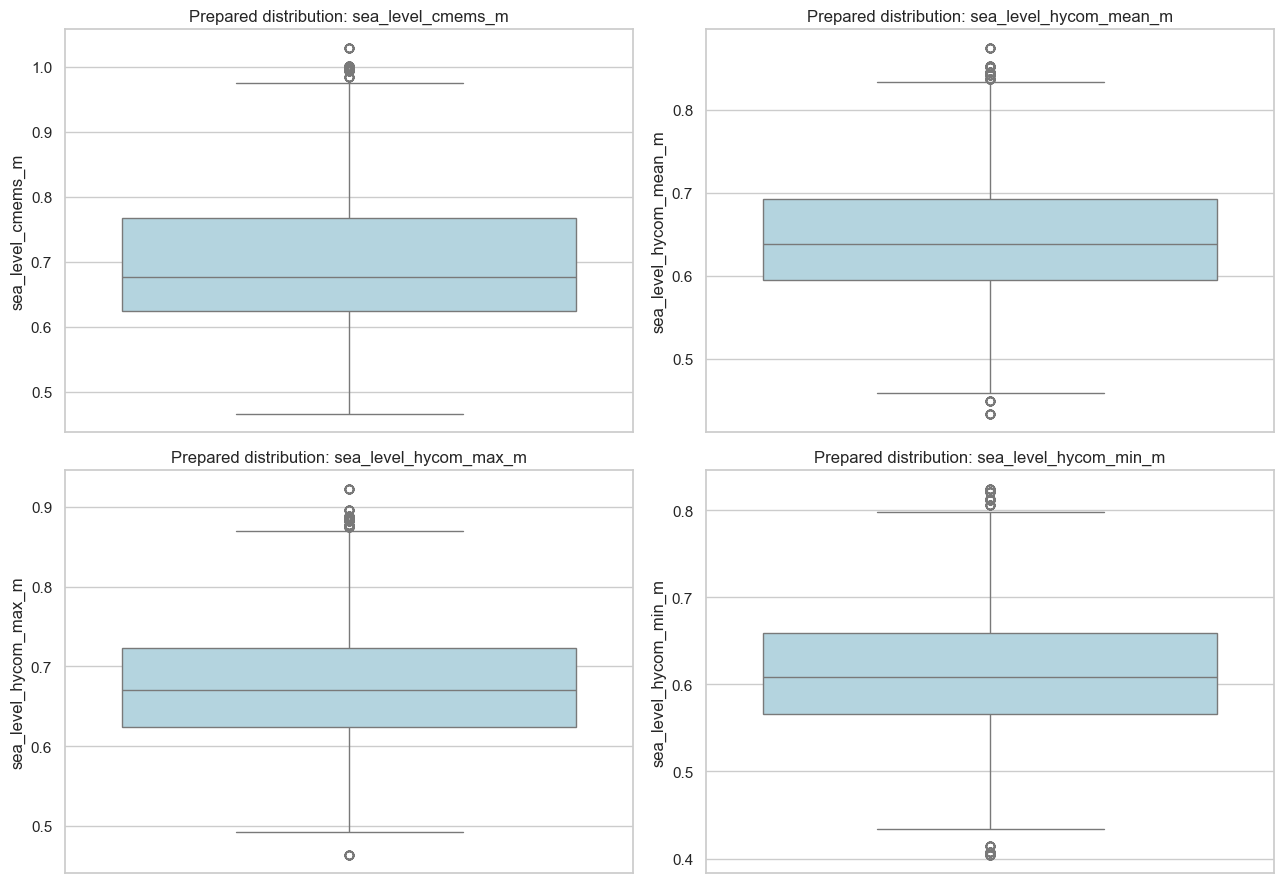

In [6]:
print(f"Rows: {len(df_prepared):,} | Columns: {len(df_prepared.columns)}")
print(f"Date range: {df_prepared['date'].min().date()} to {df_prepared['date'].max().date()}")
print("Prepared data types:")
display(df_prepared.dtypes.rename("dtype").to_frame())
print("Prepared sea-level summary:")
display(df_prepared[SEA_LEVEL_COLUMNS].describe().T.round(4))
print("Missing percentage by sea-level source:")
display(df_prepared[SEA_LEVEL_COLUMNS].isna().mean().mul(100)
        .rename("missing_pct").to_frame().round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
missing_rates = df_prepared[[f"{column}_missing" for column in SEA_LEVEL_COLUMNS]].mean().mul(100)
missing_rates.index = [column.replace("_missing", "") for column in missing_rates.index]
missing_rates.sort_values().plot(kind="barh", ax=axes[0], color="slateblue")
axes[0].set(title="Prepared data: missing sea-level measurements", xlabel="Missing (%)")

province_prepared = df_prepared.loc[df_prepared["unit_level"].eq("province")].set_index("date")
province_prepared[SEA_LEVEL_COLUMNS].resample("MS").mean().plot(ax=axes[1])
axes[1].set(title="Prepared data: monthly sea level (province)", xlabel="Date", ylabel="Sea level (m)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for column, ax in zip(SEA_LEVEL_COLUMNS, axes.flat):
    sns.boxplot(data=df_prepared, y=column, ax=ax, color="lightblue")
    ax.set_title(f"Prepared distribution: {column}")
plt.tight_layout()
plt.show()


## 5. Save the prepared data

In [7]:
output_dir = project_dir / "clean_dataset"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "sea_level_clean.csv"
df_prepared.to_csv(output_path, index=False, date_format="%Y-%m-%d", encoding="utf-8-sig")

saved_df = pd.read_csv(output_path, encoding="utf-8-sig", parse_dates=["date"])
assert saved_df.shape == df_prepared.shape
assert not saved_df.duplicated(["date", "unit_level", "district_code"]).any()
assert saved_df["sea_level_available_count"].between(0, len(SEA_LEVEL_COLUMNS)).all()
print(f"Saved: {output_path}")
print(f"File size: {output_path.stat().st_size:,} bytes")
print(f"CSV shape: {saved_df.shape}")


Saved: c:\Users\sitti\OneDrive\Desktop\Nahh ahhh v4\clean_dataset\sea_level_clean.csv
File size: 6,515,130 bytes
CSV shape: (41648, 18)
